### **Ejercicio 1**

--> **Importamos las librerías que vamos a usar**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

--> **Cargar los datos y revisamos el valor mínimo, máximo y su promedio**
Esto nos da contexto rápido.

In [3]:
smooth1 = np.load("C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 1 -  smooth_1.npy")
smooth2 = np.load("C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 2 - smooth_2.npy")

mytime1 = np.arange(len(smooth1))
mytime2 = np.arange(len(smooth2))

print(f"smooth1: shape={smooth1.shape}, min={smooth1.min():.2f}, max={smooth1.max():.2f}, mean={smooth1.mean():.2f}")
print(f"smooth2: shape={smooth2.shape}, min={smooth2.min():.2f}, max={smooth2.max():.2f}, mean={smooth2.mean():.2f}")

smooth1: shape=(1000,), min=-257.28, max=1251.97, mean=339.62
smooth2: shape=(1000,), min=-1.75, max=82.25, mean=45.85


--> **Antes de cualquier modelo, es mejor mirar los datos.**

Acá tomamos decisiones que nos permiten o limpiar los datos, o trabajar con ellos como estén. Es una buena práctica. 

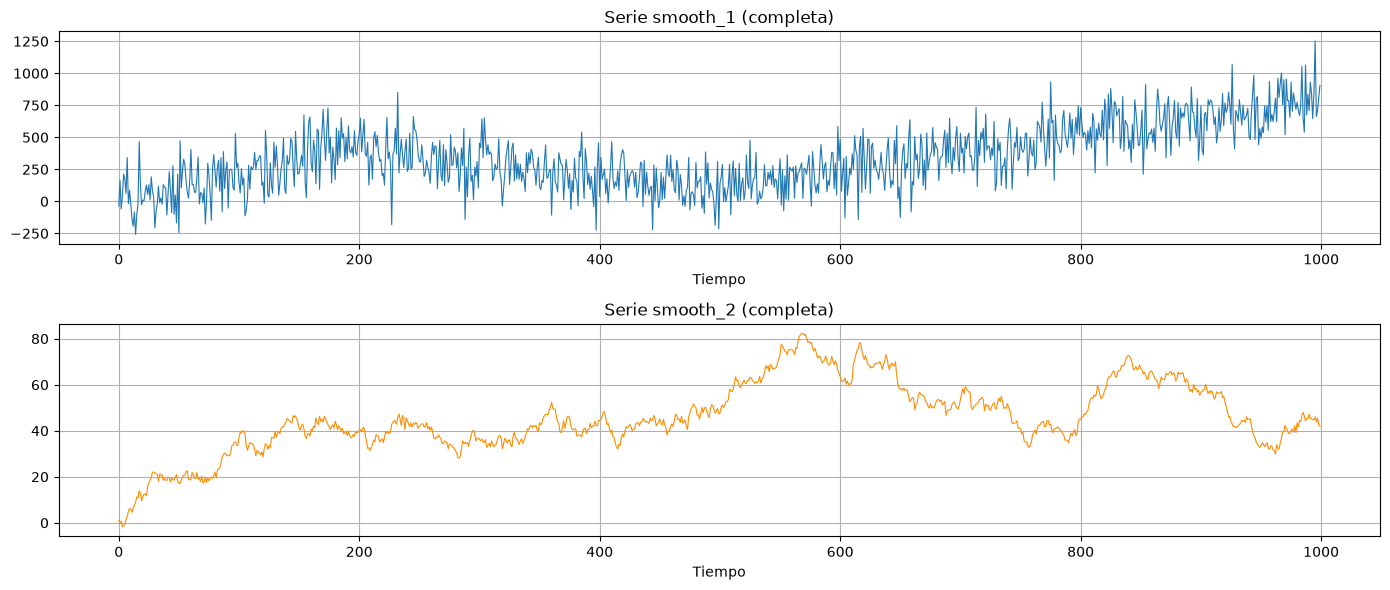

¡Figura guardada exitosamente en: C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Forecasting\tarea_2\PHASE_2\outputs\series_smooth_completas.png


In [4]:
import os
from pathlib import Path


# 1. Definir la ruta a la carpeta 'outputs' saliendo de la carpeta actual
# Path.cwd() obtiene la carpeta del notebook; .parent sube un nivel.
ruta_outputs = Path.cwd().parent / "outputs"

# 2. Crear la carpeta si por alguna razón aún no existe
ruta_outputs.mkdir(parents=True, exist_ok=True)

# 3. Definir el nombre del archivo final
archivo_guardado = ruta_outputs / "series_smooth_completas.png"

# Gráfico
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(mytime1, smooth1, lw=0.8)
axes[0].set_title("Serie smooth_1 (completa)")
axes[0].set_xlabel("Tiempo")

axes[1].plot(mytime2, smooth2, lw=0.8, color="darkorange")
axes[1].set_title("Serie smooth_2 (completa)")
axes[1].set_xlabel("Tiempo")

plt.tight_layout()

# 4. GUARDAR LA FIGURA debe ir antes de plt.show()
# Usamos str() para que matplotlib entienda la ruta de pathlib correctamente
plt.savefig(str(archivo_guardado), dpi=300, bbox_inches="tight")

# 5. Mostrar y limpiar el lienzo
plt.show()
plt.close(fig)

print(f"¡Figura guardada exitosamente en: {archivo_guardado.resolve()}")


--> **Análisis visual de la figura Series Smooth completas.png**

smooth_1: parece ruido blanco con outliers. No hay tendencia clara, no hay estacionalidad visible.

smooth_2: tendencia creciente clara (de ~0 a ~80). No hay estacionalidad evidente en el gráfico global, pero puede haberla suave.

Conclusión visual:

smooth_1 → SES (Simple Exponential Smoothing) es apropiado.

smooth_2 → Holt (doble suavizamiento) es apropiado por la tendencia.

--> **Debemos saber si hay tendencia y estacionalidad**

Si bien con la visual podemos concluir, siempre hay que probar que así sea las conjeturas que hemos dicho. 

In [5]:
def test_stationarity(series, name):
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series, autolag="AIC")
    kpss_stat, kpss_p, _, kpss_crit = kpss(series, regression="c", nlags="auto")
    
    print(f"--- {name} ---")
    print(f"ADF  p-value: {adf_p:.4f}  → {'estacionaria' if adf_p < 0.05 else 'NO estacionaria'}")
    print(f"KPSS p-value: {kpss_p:.4f}  → {'NO estacionaria' if kpss_p < 0.05 else 'estacionaria'}")

test_stationarity(smooth1, "smooth_1")
test_stationarity(smooth2, "smooth_2")

--- smooth_1 ---
ADF  p-value: 0.8898  → NO estacionaria
KPSS p-value: 0.0100  → NO estacionaria
--- smooth_2 ---
ADF  p-value: 0.0991  → NO estacionaria
KPSS p-value: 0.0100  → NO estacionaria



**ADF (Augmented Dickey-Fuller Test)**

Objetivo: Detectar si la serie tiene una raíz unitaria (lo que genera una tendencia estocástica o "paseo aleatorio").

Hipótesis:$H_0$ (Hipótesis Nula): La serie NO es estacionaria (tiene raíz unitaria).

$H_1$ (Hipótesis Alternativa): La serie es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas la hipótesis nula $\rightarrow$ Estacionaria. Si es mayor, NO es estacionaria.


**KPSS (Kwiatkowski-Phillips-Schmidt-Shin Test)**

Objetivo: Probar la estacionariedad alrededor de un nivel o una tendencia determinista. Hipótesis (¡Funciona al revés que ADF!)

$H_0$ (Hipótesis Nula): La serie ES estacionaria.

$H_1$ (Hipótesis Alternativa): La serie NO es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas $H_0$ $\rightarrow$ NO es estacionaria.

---

Recuerso para entender mejor el Forecasting

https://otexts.com/fpp3/stationarity.html

**Los dataset son Aditivos o multiplicativos**

- Modelos Aditivos: La amplitud de las variaciones o el ruido se mantiene constante a lo largo del tiempo, sin importar si la tendencia sube o baja.

- Modelos Multiplicativos: La amplitud de las variaciones crece o decrece proporcionalmente al nivel o tendencia de la serie.


--> Si es Aditiva: La desviación estándar se mantendrá casi igual en todos los bloques.

--> Si es Multiplicativa: La desviación estándar aumentará a medida que la media del bloque aumente.

In [6]:
import numpy as np
import pandas as pd


def verificar_comportamiento(data, nombre_serie, num_bloques=10):
    # Dividimos los datos en bloques iguales
    bloques = np.array_split(data, num_bloques)

    medias = [np.mean(b) for b in bloques]
    desviaciones = [np.std(b) for b in bloques]

    df_resultado = pd.DataFrame(
        {"Media del Bloque": medias, "Desviación Estándar": desviaciones}
    )

    # Calculamos la correlación entre la media y la desviación estándar
    correlacion = np.corrcoef(medias, desviaciones)[0, 1]

    print(f"=== {nombre_serie} ===")
    print(df_resultado.round(2))
    print(f"\nCorrelación entre Media y Desviación Estándar: {correlacion:.2f}")

    if correlacion > 0.7:
        print(
            "--> La serie es MULTIPLICATIVA (el ruido crece cuando crece la media).\n"
        )
    else:
        print("--> La serie es ADITIVA (el ruido es independiente del nivel).\n")


# Ejecución con tus datos
verificar_comportamiento(smooth1, "Smooth_1")
verificar_comportamiento(smooth2, "Smooth_2")

=== Smooth_1 ===
   Media del Bloque  Desviación Estándar
0            103.75               163.77
1            323.44               183.86
2            336.77               166.48
3            249.23               153.58
4            141.57               137.42
5            177.78               131.96
6            308.36               171.02
7            444.56               160.97
8            592.06               154.23
9            718.68               157.80

Correlación entre Media y Desviación Estándar: 0.21
--> La serie es ADITIVA (el ruido es independiente del nivel).

=== Smooth_2 ===
   Media del Bloque  Desviación Estándar
0             18.23                 8.28
1             39.26                 4.44
2             38.27                 4.39
3             39.92                 4.61
4             43.92                 4.18
5             67.77                 8.25
6             60.35                 8.52
7             45.28                 6.90
8             61.68          

Por lo tanto, ambos datasets Smooth_1 y smooth_2 son series aditivas. 

--> **Split train/test**

Ahora vamos a separar el dataset en parte de entrenamiento y como nos pide la tarea con 5 objservaciones para el test. 

In [7]:
train1, test1 = smooth1[:-5], smooth1[-5:]
train2, test2 = smooth2[:-5], smooth2[-5:]

time_train1 = mytime1[:-5]
time_test1  = mytime1[-5:]
time_train2 = mytime2[:-5]
time_test2  = mytime2[-5:]
# Buena práctica: guarda también los índices de tiempo para graficar limpio.

--> **Elegir y ajustar el modelo correcto**

smooth_1 → SES (sin tendencia, sin estacionalidad. Dado que no hay estacionalidad, elegimos SES ((Simple Exponential Smoothing) o Suavizamiento Exponencial Simple es un método de pronóstico utilizado para series de tiempo que no presentan tendencia ni estacionalidad)

In [8]:
model_ses1 = SimpleExpSmoothing(train1, initialization_method="estimated").fit(optimized=True)
forecast1 = model_ses1.forecast(5)

print(f"alpha óptimo (smooth_1): {model_ses1.params['smoothing_level']:.4f}")

alpha óptimo (smooth_1): 0.0699


smooth_2 → Holt (con tendencia, sin estacionalidad) modelo de Suavizado Exponencial Doble de Holt. Es un método de pronóstico para series de tiempo que se utiliza cuando los datos presentan una tendencia clara pero no tienen estacionalidad.

In [9]:
model_holt2 = Holt(train2, initialization_method="estimated").fit(optimized=True)
forecast2 = model_holt2.forecast(5)

print(f"alpha (nivel)    : {model_holt2.params['smoothing_level']:.4f}")
print(f"beta  (tendencia): {model_holt2.params['smoothing_trend']:.4f}")

alpha (nivel)    : 0.9783
beta  (tendencia): 0.0000


smooth_1 no tiene tendencia → SES basta.
smooth_2 tiene tendencia → Holt (doble suavizamiento) es el modelo correcto. SES se quedaría plano y subestimaría.

Si hubieramos detectado estacionalidad, usaríamos Holt-Winters (ExponentialSmoothing(..., seasonal="add", seasonal_periods=12)).

El peso de la memoria ALFA
Mide qué tan rápido reacciona el modelo a los datos más recientes para actualizar el valor base (el nivel).

- Si $\alpha$ está cerca de 1 (Memoria corta / Cortoplacista):El modelo olvida rápido el pasado y se amolda de inmediato al último dato observado. Es ideal para datos volátiles o que cambian de nivel bruscamente.

- Si $\alpha$ está cerca de 0 (Memoria larga / Suavizador):El modelo le da muy poco peso al dato más reciente y prefiere un promedio ponderado de toda la historia. Ignora los picos raros o el "ruido".

BETA El peso de la memoria de la TendenciaMide qué tan rápido se adapta el modelo a cambios en la inclinación o pendiente de la serie (la tendencia).

- Si $\beta$ está cerca de 1:El modelo cambia la dirección de la tendencia muy rápido si los últimos datos suben o bajan abruptamente.

- Si $\beta$ está cerca de 0:El modelo mantiene la inclinación de la tendencia fija y constante en el tiempo; no cambia la pendiente por un par de datos que hayan subido o bajado

Conclusión de este punto

Serie 1 (smooth_1): 
- $\alpha = 0.0699$ (Muy bajo)Significado: El modelo le da poquísima importancia a la última observación aislada (solo un 7%).Lectura: Considera que los datos diarios tienen mucho ruido/azar, por lo que prefiere calcular un promedio muy estable basado en la historia antigua para no sobrerreaccionar a fluctuaciones pasajeras.

Serie 2 (Holt2): 
- $\alpha = 0.9783$ (Muy alto) y $\beta = 0.0000$ (Cero puro)Alfa ($\alpha = 0.9783$): Es casi $1$. El nivel se actualiza casi en un 98% con el último dato recibido. Si el dato de hoy sube, la base del modelo sube inmediatamente a ese valor.Beta ($\beta = 0.0000$): Es exactamente cero. Significa que la tendencia es totalmente rígida o constante. El modelo calcula una inclinación inicial al principio y la mantiene fija sin alterarla a lo largo del tiempo, sin importar si los datos recientes parecen acelerarse o desacelerarse.

--> **Evaluación con múltiples méstricas**

In [10]:
def evaluate(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((np.array(y_true) - np.array(y_pred)) / np.array(y_true))) * 100
    print(f"--- {name} ---")
    print(f"MSE : {mse:,.4f}")
    print(f"RMSE: {rmse:,.4f}")
    print(f"MAE : {mae:,.4f}")
    print(f"MAPE: {mape:.2f}%")
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "MAPE": mape}

metrics1 = evaluate(test1, forecast1, "SES - smooth_1")
print()
metrics2 = evaluate(test2, forecast2, "Holt - smooth_2")

--- SES - smooth_1 ---
MSE : 52,041.5311
RMSE: 228.1261
MAE : 163.2318
MAPE: 16.56%

--- Holt - smooth_2 ---
MSE : 3.5812
RMSE: 1.8924
MAE : 1.6543
MAPE: 3.83%


MSE/RMSE: castigan errores grandes.

MAE: robusto a outliers.

MAPE: interpretable como % de error.

-->  **Diagnóstico de residuos**
No se puede fiar solo del MSE. Se verifica que los residuos sean ruido blanco.

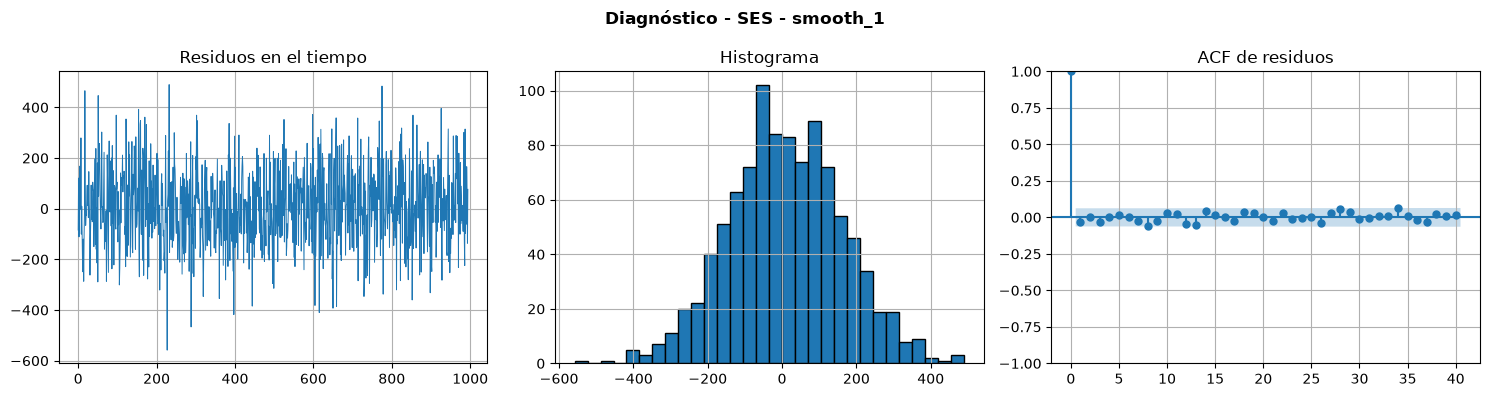

Ljung-Box p-value: 0.6112  (>0.05 → residuos sin autocorrelación)


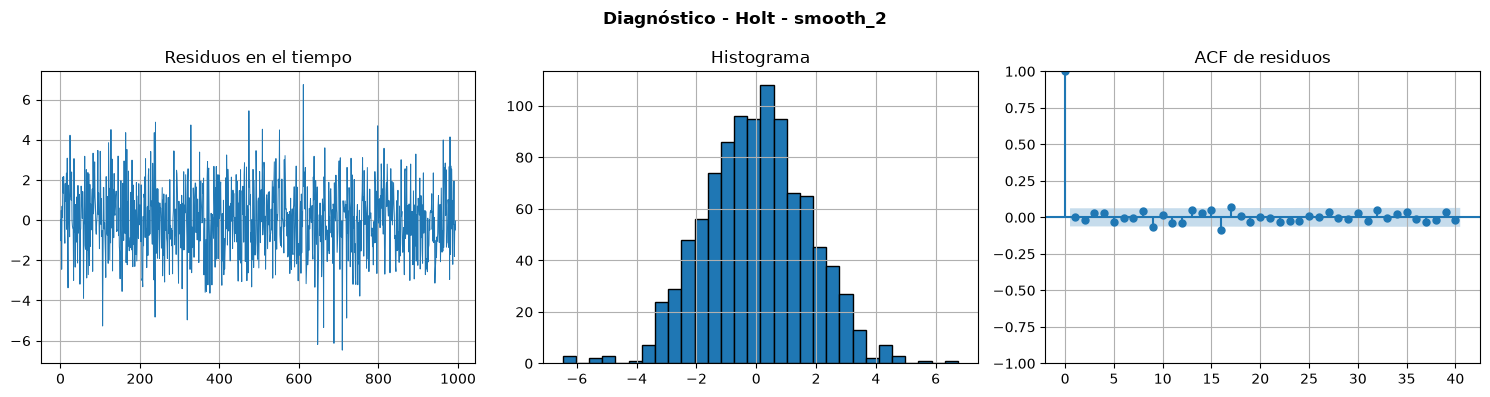

Ljung-Box p-value: 0.5080  (>0.05 → residuos sin autocorrelación)


In [11]:
def residual_diagnostics(model, name):
    resid = model.resid
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(resid, lw=0.7); axes[0].set_title("Residuos en el tiempo")
    axes[1].hist(resid, bins=30, edgecolor="k"); axes[1].set_title("Histograma")
    plot_acf(resid, ax=axes[2], lags=40); axes[2].set_title("ACF de residuos")
    fig.suptitle(f"Diagnóstico - {name}", fontweight="bold")
    plt.tight_layout(); plt.show()
    
    from statsmodels.stats.diagnostic import acorr_ljungbox
    lb = acorr_ljungbox(resid, lags=[10], return_df=True)
    print(f"Ljung-Box p-value: {lb['lb_pvalue'].values[0]:.4f}  (>0.05 → residuos sin autocorrelación)")

residual_diagnostics(model_ses1, "SES - smooth_1")
residual_diagnostics(model_holt2, "Holt - smooth_2")

¿Qué busacamos en la gráfica anterior?

- ACF sin picos significativos → residuos no autocorrelacionados 

- Ljung-Box p > 0.05 → no rechazas ruido blanco 

- Histograma aproximadamente simétrico.

--> **Visualizamos**

train + test + forecast

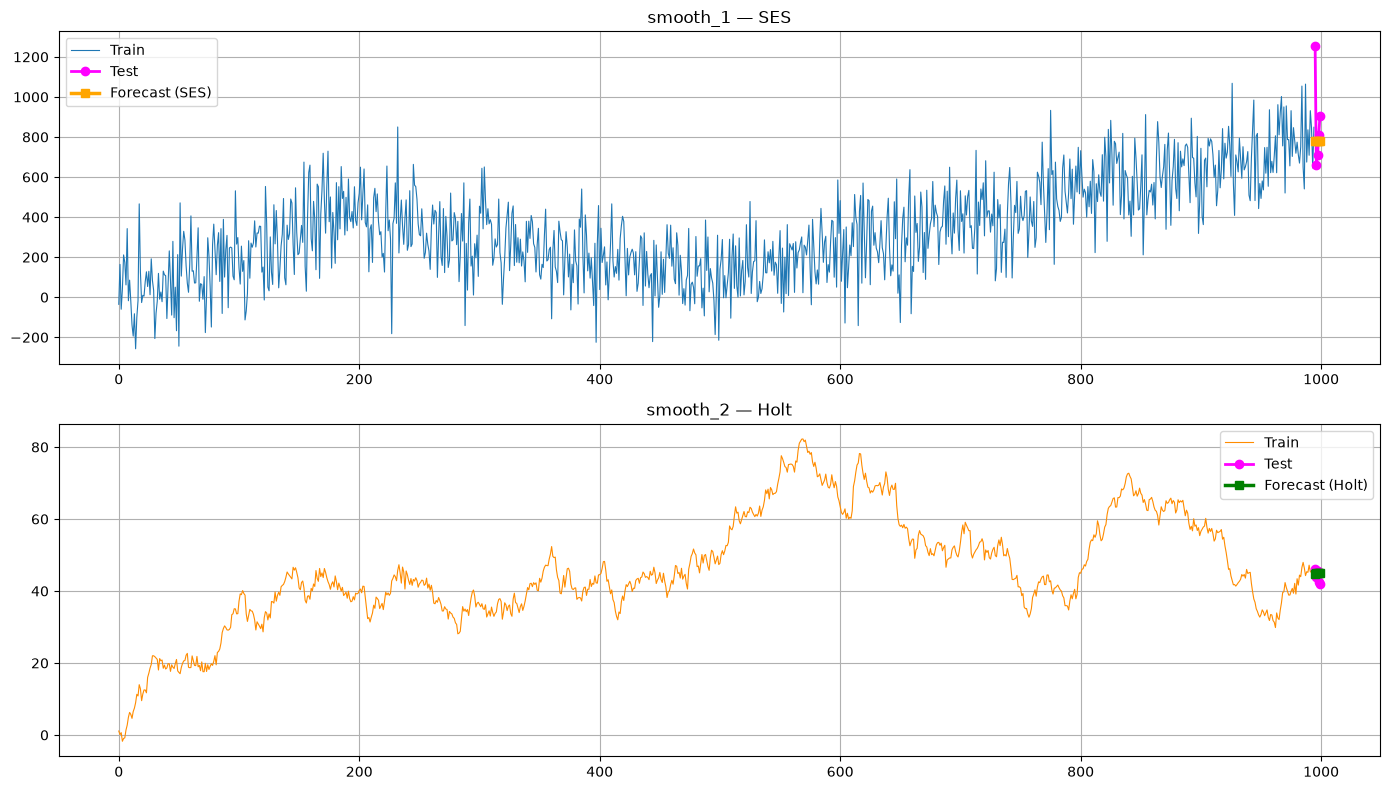

¡Figura guardada exitosamente en: C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Forecasting\tarea_2\PHASE_2\outputs\Visualización Final Train, Test y Forecast.png


In [12]:
import os
from pathlib import Path


# 1. Definir la ruta a la carpeta 'outputs' saliendo de la carpeta actual
# Path.cwd() obtiene la carpeta del notebook; .parent sube un nivel.
ruta_outputs = Path.cwd().parent / "outputs"

# 2. Crear la carpeta si por alguna razón aún no existe
ruta_outputs.mkdir(parents=True, exist_ok=True)

# 3. Definir el nombre del archivo final
archivo_guardado2 = ruta_outputs / "Visualización Final Train, Test y Forecast.png"

# Gráfico
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# smooth_1
axes[0].plot(time_train1, train1, label="Train", lw=0.8)
axes[0].plot(time_test1, test1, label="Test", color="magenta", lw=2, marker="o")
axes[0].plot(time_test1, forecast1, label="Forecast (SES)", color="orange", lw=2.5, marker="s")
axes[0].set_title("smooth_1 — SES"); axes[0].legend()

# smooth_2
axes[1].plot(time_train2, train2, label="Train", lw=0.8, color="darkorange")
axes[1].plot(time_test2, test2, label="Test", color="magenta", lw=2, marker="o")
axes[1].plot(time_test2, forecast2, label="Forecast (Holt)", color="green", lw=2.5, marker="s")
axes[1].set_title("smooth_2 — Holt"); axes[1].legend()

plt.tight_layout()

# 4. GUARDAR LA FIGURA Debe ir antes de plt.show()
# Usamos str() para que matplotlib entienda la ruta de pathlib correctamente
plt.savefig(str(archivo_guardado2), dpi=300, bbox_inches="tight")

# 5. Mostrar y limpiar el lienzo
plt.show()
plt.close(fig)

print(f"¡Figura guardada exitosamente en: {archivo_guardado2.resolve()}")

--> **Conclusión del Ejercicio 1**

Esta serie se mmodeló con SES porque la Serie smooth_1: Los tests ADF (p = 0.8998) y KPSS (p = 0.0100) indican que la serie no es estacionaria, no tiene tendencia y además es aditiva. Por tanto, el modelo Simple Exponential Smoothing (SES) es el apropiado. El MSE en test fue de 52.041.5311, con residuos que superan el test de Ljung-Box (p = 0.6112), indicando que no queda estructura sin capturar.

Esta serie se modeló con Holt porque la Serie smooth_2: Los tests ADF (p = 0.0991) y KPSS (p = 0.0100) indican no estacionariedad, si hay tenencia y es aditiva. La fuerza de tendencia es alta, mientras que la estacionalidad es débil. Por tanto, el modelo Holt (doble suavizamiento) es el apropiado, capturando el nivel y la tendencia. El MSE en test fue de 3.5812, notablemente mejor que SES confirmando que la tendencia debe modelarse

SES - smooth_1 
- MSE : 52,041.5311
- RMSE: 228.1261
- MAE : 163.2318
- MAPE: 16.56%

Holt - smooth_2
- MSE : 3.5812
- RMSE: 1.8924
- MAE : 1.6543
- MAPE: 3.83%